 ## 1. Inicjalizacja i Konfiguracja Parametrów



 Miejsce na importy bibliotek oraz definicje wszystkich ścieżek, dat, horyzontów walidacji i parametrów modelu.

In [ ]:
import os
import io
import time
import warnings
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
from datetime import timedelta
from bayes_opt import BayesianOptimization
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import Ridge

warnings.filterwarnings('ignore')
np.random.seed(123)
os.environ['TZ'] = 'UTC'

# --- Konfiguracja Ścieżek ---
path_events = r"W:\Dzial Business process\Dzial Analiz\OSOBISTE\RAFAŁ\Wewnętrzne\Baza wydarzeń.xlsx"
path_pogoda = r"raport pogodowy - wykresy ATV.xlsx"
nazwa_pliku_prognoza = "ATV_prognoza_2026_11.xlsx"

# --- Parametry Czasowe i Horyzonty Walidacji ---
zmienna_obj = "ATV"  # Możliwa wartość: "ATV" lub "logATV"
Start_date = pd.to_datetime("2021-08-05").date()
last_update_date = pd.to_datetime("2026-10-12").date()
End_date = last_update_date - timedelta(days=1)
Start_prognozowanego_miesiaca = pd.to_datetime("2026-11-01").date()
End_pred = pd.to_datetime("2026-11-30").date()

# Horyzont ~2 miesięcy (60 dni = 1460h) dopasowany do docelowego zadania prognozy
HORIZON_HOURS = (365 * 24) // 6  # 1460 godzin (~2 miesiące)
BACKTEST_SPLITS = 6              # 6 foldów = 8760 godzin (pełny ostatni rok jako Test Końcowy)
TUNING_SPLITS = 3                # 3 foldy walidacyjne (po 1460h) wewnątrz zbioru sprzed backtestu
WEATHER_HORIZON_DAYS = 14        # Liczba dni dostępnej prognozy pogody od momentu startu predykcji

# --- Definicja Zmiennych i Okien ---
lags_def = [8736]
windows_def = [672, 8736]
lags_4w = [168, 336, 504, 672]
max_dropna_lag = max(lags_def + windows_def)

cat_cols = ["Label", "Holiday", "Hour", "Daypart", "Weekday", "Month", "Year"]

# --- Cechy dla modelu Trendu (Ridge) ---
zmienne_trendu = [
    "Trend",
    "Year_sin", "Year_cos",       
    "Weekday_sin", "Weekday_cos", 
    "Hour_sin", "Hour_cos"        
]

# --- Cechy dla modelu Odchyleń (XGBoost) - bez trygonometrii i tekstów ---
zmienne_xgboost = [
    "Label", "Rank", "Holiday", "Weekend", 
    "Hour_int", "Weekday_int", "Day_of_year",
    "Sunset", 
    "Hours_after_sunset", 
    "After_sunset", 
    "Temperatura maks.", "%Czas opadów",
    "Lag_mean_4_weeks", "Is_event_in_Lag_mean"
 ]

for lag in lags_def:
    zmienne_xgboost.extend([f"Lag_{lag}", f"Is_event_in_Lag_{lag}"])
for w in windows_def:
    zmienne_xgboost.extend([f"Roll_mean_{w}", f"Is_event_in_Roll_{w}"])



 ## 2. Funkcje Pomocnicze i Silnik Rekurencyjny (Brak Data Leakage)



 Funkcje odpowiadające za bezpieczne przetwarzanie cech po podziale danych oraz ujednoliconą pętlę rekurencyjną wykorzystywaną zarówno w testach/walidacji, jak i w prognozie produkcyjnej.

In [ ]:
def parse_nielsen_datetime(df):
    df_out = df.copy()
    df_out['Date'] = pd.to_datetime(df_out['Date']).dt.normalize()
    times_raw = df_out['Daypart'].astype(str).str.extract(r'(\d{4})', expand=False)
    valid_mask = times_raw.notna()
    df_out = df_out[valid_mask].copy()
    times_raw = times_raw[valid_mask]

    time_strings = times_raw.str[:2] + ":" + times_raw.str[2:] + ":00"
    df_out['DT'] = df_out['Date'] + pd.to_timedelta(time_strings)
    df_out['Date'] = df_out['DT'].dt.date
    df_out['Time'] = df_out['DT'].dt.strftime('%H:%M:%S')
    df_out['DT'] = df_out['DT'].dt.tz_localize('UTC')
    return df_out.drop(columns=['Daypart'])


def dodaj_cechy_deterministyczne(df_base, events_df, holiday_df, ddt_df, pogoda_df, trend_start=0):
    """Tworzy wyłącznie cechy kalendarzowe, astronomiczne i zaplanowane wydarzenia (bez lagów i średnich z przyszłości)."""
    df = df_base.sort_values("DT").copy()

    # Wydarzenia sportowe / specjalne
    ev_sub = events_df[events_df["End_DT"] >= df["DT"].min()].sort_values("DT")
    if not ev_sub.empty:
        df = pd.merge_asof(df, ev_sub[["DT", "End_DT", "Label", "Rank"]], on="DT", direction="backward")
        df.loc[df["DT"] >= df["End_DT"], ["Label", "Rank"]] = None
        df.drop(columns="End_DT", inplace=True, errors="ignore")
    else:
        df["Label"], df["Rank"] = None, None

    df["Label"] = df["Label"].fillna("Brak")
    df["Rank"] = df["Rank"].fillna(0.0)
    df["event_flag"] = (df["Label"] != "Brak").astype(int)

    # Święta i zachody słońca
    df = df.merge(holiday_df, on="Date", how="left")
    df["Holiday"] = df["Holiday"].fillna("Brak")
    df["event_or_holiday_flag"] = (df["event_flag"] | (df["Holiday"] != "Brak")).astype(int)

    df = df.merge(ddt_df[["Date", "Sunset"]], on="Date", how="left")
    df["Sunset"] = pd.to_timedelta(df["Sunset"].astype(str), errors="coerce").dt.total_seconds() / 3600.0

    # Surowa pogoda (odchylenia od średniej miesięcznej zostaną policzone dopiero po podziale zbioru)
    df = df.merge(pogoda_df[["Date", "Temp_raw", "Opady_raw"]], on="Date", how="left")

    # Cechy kalendarzowe i cykliczne
    df["Hour_int"] = df["DT"].dt.hour
    df["Hour"] = df["Hour_int"].astype(str).str.zfill(2)
    df["Weekday_int"] = df["DT"].dt.weekday
    df["Weekday"] = df["DT"].dt.day_name()
    df["Month_int"] = df["DT"].dt.month
    df["Month"] = df["DT"].dt.month_name()
    df["Quarter_int"] = df["DT"].dt.quarter
    df["Year_int"] = df["DT"].dt.year
    df["Year"] = df["Year_int"].astype(str)
    df["Day_of_year"] = df["DT"].dt.dayofyear

    time_minutes = df["Hour_int"] * 60 + df["DT"].dt.minute
    df["Daypart"] = np.select(
        [
            (time_minutes >= 360) & (time_minutes < 510),
            (time_minutes >= 510) & (time_minutes < 900),
            (time_minutes >= 900) & (time_minutes < 1020),
            (time_minutes >= 1020) & (time_minutes < 1380)
        ],
        ["Morning Time", "Day Time", "Early Fringe", "Prime Time"],
        default="Late Night"
    )

    df["Hour_sin"] = np.sin(2 * np.pi * df["Hour_int"] / 24.0)
    df["Hour_cos"] = np.cos(2 * np.pi * df["Hour_int"] / 24.0)
    df["Weekday_sin"] = np.sin(2 * np.pi * df["Weekday_int"] / 7.0)
    df["Weekday_cos"] = np.cos(2 * np.pi * df["Weekday_int"] / 7.0)
    df["Year_sin"] = np.sin(2 * np.pi * df["Day_of_year"] / 365.25)
    df["Year_cos"] = np.cos(2 * np.pi * df["Day_of_year"] / 365.25)

    df["PrimeTime"] = df["Hour_int"].between(17, 22).astype(int)
    df["PrimeTimeNarrow"] = df["Hour_int"].between(19, 21).astype(int)
    df["Weekend"] = (df["Weekday_int"] >= 5).astype(int)

    df["Hours_after_sunset"] = df["Hour_int"] - df["Sunset"]
    df["After_sunset"] = (df["Hours_after_sunset"] >= 0).astype(int)

    df = df.sort_values("DT").drop_duplicates(subset=["DT"]).reset_index(drop=True)
    df["Trend"] = np.arange(trend_start, trend_start + len(df))
    return df


def wyznacz_statystyki_treningowe(df_train_raw):
    """Wyznacza słownik kategorii oraz średnie miesięczne pogody wyłącznie na zbiorze treningowym."""
    srednie_pogoda = (
        df_train_raw[["Date", "Month_int", "Temp_raw", "Opady_raw"]]
        .drop_duplicates(subset=["Date"])
        .groupby("Month_int")[["Temp_raw", "Opady_raw"]]
        .mean()
        .reset_index()
        .rename(columns={"Temp_raw": "Temp_srednia_msc", "Opady_raw": "Opady_srednia_msc"})
    )

    kategorie_map = {}
    for col in cat_cols:
        if col in df_train_raw.columns:
            kategorie_map[col] = pd.Index(df_train_raw[col].astype(str).unique())

    return srednie_pogoda, kategorie_map


def aplikuj_pogode_bez_przecieku(df_in, srednie_pogoda, cutoff_date=None):
    """Liczy odchylenia pogody od średniej z treningu; powyżej 14 dni od cutoff_date zeruje odchylenie."""
    df = df_in.merge(srednie_pogoda, on="Month_int", how="left")
    if cutoff_date is not None:
        limit_pogody = cutoff_date + timedelta(days=WEATHER_HORIZON_DAYS)
        mask_znana = df["Date"] <= limit_pogody
    else:
        mask_znana = pd.Series(True, index=df.index)

    df["Temperatura maks."] = np.where(
        mask_znana & df["Temp_raw"].notna(),
        df["Temp_raw"] - df["Temp_srednia_msc"],
        0.0
    )
    df["%Czas opadów"] = np.where(
        mask_znana & df["Opady_raw"].notna(),
        df["Opady_raw"] - df["Opady_srednia_msc"],
        0.0
    )
    return df.drop(columns=["Temp_srednia_msc", "Opady_srednia_msc"])


def koduj_zmienne_do_macierzy(df_in, kategorie_map):
    """Tworzy macierz cech X z zakodowanymi kategoriami bez nadpisywania tekstowych etykiet w głównej ramce."""
    X = df_in[zmienne_xgboost].copy()
    for col, cats in kategorie_map.items():
        if col in X.columns:
            X[col] = pd.Categorical(X[col].astype(str), categories=cats).codes
    return X.astype(float)


def zbuduj_zbior_treningowy(df_train_raw):
    """
    Oblicza lagi i średnie kroczące wyłącznie wewnątrz przekazanego podzbioru treningowego (po podziale).
    Zwraca gotowe X_train, y_train, df_train_model oraz wyznaczone na treningu statystyki.
    """
    srednie_pogoda, kategorie_map = wyznacz_statystyki_treningowe(df_train_raw)
    df = aplikuj_pogode_bez_przecieku(df_train_raw.copy(), srednie_pogoda, cutoff_date=None)

    for lag in lags_def:
        df[f"Lag_{lag}"] = df["ATV"].shift(lag)
        df[f"Is_event_in_Lag_{lag}"] = df["event_flag"].shift(lag).fillna(0).astype(int)

    for w in windows_def:
        df[f"Roll_mean_{w}"] = df["ATV"].shift(1).rolling(w).mean()
        df[f"Is_event_in_Roll_{w}"] = df["event_flag"].shift(1).rolling(w).max().fillna(0).astype(int)

    df["Lag_mean_4_weeks"] = sum(df["ATV"].shift(l) for l in lags_4w) / 4.0
    df["Is_event_in_Lag_mean"] = (
        pd.concat([df["event_or_holiday_flag"].shift(l) for l in lags_4w], axis=1)
        .max(axis=1).fillna(0).astype(int)
    )

    wymagane_kolumny = list(set(zmienne_xgboost + zmienne_trendu))
    df_model = df.iloc[max_dropna_lag:].dropna(subset=wymagane_kolumny + [zmienna_obj]).reset_index(drop=True)
    X_train = koduj_zmienne_do_macierzy(df_model, kategorie_map)
    y_train = df_model[zmienna_obj].copy()
    return X_train, y_train, df_model, srednie_pogoda, kategorie_map


def prognozuj_rekurencyjnie(df_hist_raw, df_future_raw, trend_model, xgb_model, srednie_pogoda, kategorie_map):
    """
    Generuje prognozę (zarówno dla testu/backtestu, jak i dla produkcji) jedną i tą samą pętlą rekurencyjną.
    Wartości ATV w zbiorze df_future_raw są przed pętlą bezwzględnie czyszczone (np.nan), aby wykluczyć przeciek.
    """
    cutoff_date = df_hist_raw["Date"].max()

    df_hist = df_hist_raw.tail(max_dropna_lag).copy()
    df_fut = df_future_raw.copy()
    df_fut["ATV"] = np.nan
    df_fut["logATV"] = np.nan

    df_combined = pd.concat([df_hist, df_fut], ignore_index=True)
    df_combined = aplikuj_pogode_bez_przecieku(df_combined, srednie_pogoda, cutoff_date=cutoff_date)

    # Inicjalizacja pustych kolumn lag/rolling przed pętlą
    dynamic_cols = ["Lag_mean_4_weeks", "Is_event_in_Lag_mean"]
    for lag in lags_def:
        dynamic_cols.extend([f"Lag_{lag}", f"Is_event_in_Lag_{lag}"])
    for w in windows_def:
        dynamic_cols.extend([f"Roll_mean_{w}", f"Is_event_in_Roll_{w}"])
    for col in dynamic_cols:
        df_combined[col] = np.nan

    start_idx = len(df_hist)
    end_idx = len(df_combined)

    # Przygotowanie numerycznej macierzy X_mat dla szybkiej pętli (tylko zmienne XGBoost)
    X_df = koduj_zmienne_do_macierzy(df_combined, kategorie_map)
    X_mat = X_df.to_numpy(dtype=np.float64)
    col_pos = {col: idx for idx, col in enumerate(zmienne_xgboost)}

    # Predykcja trendu bazowego zależy tylko od cech deterministycznych - odpytujemy df_combined!
    trend_preds = trend_model.predict(df_combined.iloc[start_idx:][zmienne_trendu])

    atv_values = df_combined["ATV"].to_numpy(dtype=np.float64)
    event_values = df_combined["event_flag"].to_numpy(dtype=np.int32)
    ev_hol_values = df_combined["event_or_holiday_flag"].to_numpy(dtype=np.int32)

    idx_lag_mean_4w = col_pos["Lag_mean_4_weeks"]
    idx_ev_lag_mean = col_pos["Is_event_in_Lag_mean"]
    lag_positions = [(lag, col_pos[f"Lag_{lag}"], col_pos[f"Is_event_in_Lag_{lag}"]) for lag in lags_def]
    win_positions = [(w, col_pos[f"Roll_mean_{w}"], col_pos[f"Is_event_in_Roll_{w}"]) for w in windows_def]

    booster = xgb_model.get_booster()

    # Rekurencyjna pętla godzinowa krok po kroku
    for step, i in enumerate(range(start_idx, end_idx)):
        for lag, pos_lag, pos_ev_lag in lag_positions:
            X_mat[i, pos_lag] = atv_values[i - lag]
            X_mat[i, pos_ev_lag] = event_values[i - lag]

        for w, pos_roll, pos_ev_roll in win_positions:
            X_mat[i, pos_roll] = np.mean(atv_values[i - w : i])
            X_mat[i, pos_ev_roll] = np.max(event_values[i - w : i])

        X_mat[i, idx_lag_mean_4w] = (
            atv_values[i - 168] + atv_values[i - 336] + atv_values[i - 504] + atv_values[i - 672]
        ) * 0.25
        X_mat[i, idx_ev_lag_mean] = max(
            ev_hol_values[i - 168], ev_hol_values[i - 336], ev_hol_values[i - 504], ev_hol_values[i - 672]
        )

        # Predykcja odchylenia (XGBoost) + składowa trendu (Ridge)
        resid_pred = float(booster.inplace_predict(X_mat[i : i + 1])[0])
        pred_combined = trend_preds[step] + resid_pred

        if zmienna_obj == "logATV":
            df_combined.at[i, "logATV"] = pred_combined
            atv_values[i] = np.expm1(pred_combined)
        else:
            atv_values[i] = pred_combined

    # Zapisanie wyliczonych w pętli cech oraz prognoz z powrotem do ramki wynikowej
    df_combined["ATV"] = atv_values
    for col in dynamic_cols:
        df_combined.loc[start_idx:, col] = X_mat[start_idx:, col_pos[col]]

    df_out = df_combined.iloc[start_idx:].copy().reset_index(drop=True)
    df_out["ATV_predykcja"] = df_out["ATV"]
    return df_out



 ## 3. Import i Przetwarzanie Danych Historycznych (Tylko Cechy Deterministyczne)



 Wczytanie surowych danych i połączenie ze słownikami zewnętrznymi bez wyliczania lagów i średnich kroczących przed podziałem zbioru.

In [13]:
print("Wczytywanie i przetwarzanie danych deterministycznych...")

# --- Dane Główne (ATV) ---
dane_surowe = pd.read_csv("Time ATV_hourly_TSV.csv", skiprows=10, decimal=",").rename(columns={"TRP (avgW)": "ATV"})
dane_surowe = parse_nielsen_datetime(dane_surowe)
dane_surowe = dane_surowe.set_index('DT').resample('1h').asfreq().reset_index()
dane_surowe["Date"] = dane_surowe["DT"].dt.date
dane_surowe["Time"] = dane_surowe["DT"].dt.strftime('%H:%M:%S')
dane_surowe = dane_surowe[["DT", "Date", "Time", "ATV"]].sort_values("DT").reset_index(drop=True)
dane_surowe["logATV"] = np.log1p(dane_surowe["ATV"])

# --- Zewnętrzne Źródła ---
Events_dane = pd.read_excel(path_events, sheet_name="Events_full")
Events_dane["DT"] = pd.to_datetime(Events_dane["DT"], utc=True)
Events_dane["End_DT"] = Events_dane["DT"] + pd.to_timedelta(Events_dane["Duration"].astype(str))
Events_dane = Events_dane.sort_values("DT")

Holiday_dane = pd.read_excel(path_events, sheet_name="Holiday_full")
Holiday_dane["Date"] = pd.to_datetime(Holiday_dane["Data"]).dt.date
Holiday_dane = Holiday_dane[["Date", "Holiday"]].drop_duplicates()

DDT_dane = pd.read_excel(path_events, sheet_name="DDT")
DDT_dane["Date"] = pd.to_datetime(DDT_dane["Date"]).dt.date
DDT_dane = DDT_dane.drop_duplicates(subset=["Date"])

Pogoda_dane = pd.read_excel(path_pogoda)
Pogoda_dane["Date"] = pd.to_datetime(Pogoda_dane["Data"]).dt.date
Pogoda_dane = Pogoda_dane[["Date", "Temperatura maks.", "%Czas opadów"]].drop_duplicates(subset=["Date"], keep="last")
Pogoda_dane[["Temperatura maks.", "%Czas opadów"]] = Pogoda_dane[["Temperatura maks.", "%Czas opadów"]].apply(pd.to_numeric, errors="coerce")
Pogoda_dane = Pogoda_dane.rename(columns={"Temperatura maks.": "Temp_raw", "%Czas opadów": "Opady_raw"})

# --- Złożenie głównej tabeli deterministycznej (bez lagów!) ---
dane = dodaj_cechy_deterministyczne(
    dane_surowe, Events_dane, Holiday_dane, DDT_dane, Pogoda_dane, trend_start=0
)
dane = dane.loc[dane["Date"] <= End_date].reset_index(drop=True)

print(f"Wczytano {len(dane)} godzin historii (od {dane['Date'].min()} do {dane['Date'].max()}).")



Wczytywanie i przetwarzanie danych deterministycznych...
Wczytano 50638 godzin historii (od 2021-01-01 do 2026-10-11).


 ## 4. Podział Chronologiczny, Optymalizacja i Zamrożenie Parametrów



 Wydzielamy ostatni rok danych (`8760` godzin = 6 foldów po ~2 miesiące) jako nietknięty zbiór do Backtestu Końcowego.



 Dobór hiperparametrów odbywa się **wyłącznie na wcześniejszej historii** przy użyciu pętli rekurencyjnej, po czym parametry zostają **zamrożone**.

In [14]:
# Sztywna granica czasowa oddzielająca zbiór strojenia od rocznego backtestu końcowego
backtest_total_hours = BACKTEST_SPLITS * HORIZON_HOURS  # 8760 godzin (365 dni)
split_backtest_idx = len(dane) - backtest_total_hours

df_tuning_raw = dane.iloc[:split_backtest_idx].copy().reset_index(drop=True)
print(f"Zbiór do strojenia hiperparametrów: {df_tuning_raw['Date'].min()} -> {df_tuning_raw['Date'].max()} ({len(df_tuning_raw)}h)")
print(f"Zbiór zamrożonego Backtestu (1 rok): {dane.iloc[split_backtest_idx]['Date']} -> {dane['Date'].max()} ({backtest_total_hours}h)")

# Przygotowanie foldów walidacyjnych wewnątrz zbioru df_tuning_raw (horyzont = 1460h, czyli ~2 miesiące)
tscv_tuning = TimeSeriesSplit(n_splits=TUNING_SPLITS, test_size=HORIZON_HOURS)
tuning_folds_cache = []

for train_idx, val_idx in tscv_tuning.split(df_tuning_raw):
    df_tr_fold = df_tuning_raw.iloc[train_idx].copy()
    df_val_fold = df_tuning_raw.iloc[val_idx].copy()

    # Budowa cech treningowych wyłącznie na historii sprzed startu okna walidacyjnego
    X_tr, y_tr, df_model_tr, sr_pogoda, kat_map = zbuduj_zbior_treningowy(df_tr_fold)

    tuning_folds_cache.append({
        "df_tr_fold": df_tr_fold,
        "df_val_fold": df_val_fold,
        "X_tr": X_tr,                  # Ucięta macierz tylko z cechami XGBoost
        "df_model_tr": df_model_tr,    # Pełna ramka treningowa dla modelu Ridge
        "y_tr": y_tr,                  # Surowe wartości ATV
        "sr_pogoda": sr_pogoda,
        "kat_map": kat_map,
        "y_val_true": df_val_fold["ATV"].to_numpy(dtype=np.float64)
    })

best_n_estimators_list = []

def xgb_evaluate_recursive(ridge_alpha, max_depth, learning_rate, subsample, colsample_bytree, min_child_weight):
    rmse_scores, iterations = [], []
    params = {
        "max_depth": int(round(max_depth)),
        "learning_rate": float(learning_rate),
        "subsample": float(subsample),
        "colsample_bytree": float(colsample_bytree),
        "min_child_weight": float(min_child_weight),
        "tree_method": "hist",
        "random_state": 123,
        "n_jobs": -1
    }

    for fold_data in tuning_folds_cache:
        # 1. DYNAMICZNE DOPASOWANIE TRENDU (Ridge) Z AKTUALNIE TESTOWANĄ ALFĄ
        trend_model = Ridge(alpha=ridge_alpha)
        
        # Prawidłowe odpytanie pełnej ramki (df_model_tr) o zmienne trendu
        trend_model.fit(fold_data["df_model_tr"][zmienne_trendu], fold_data["y_tr"])
        y_tr_resid = fold_data["y_tr"] - trend_model.predict(fold_data["df_model_tr"][zmienne_trendu])

        # Wydzielenie ogona do Early Stopping (ostatnie 720h)
        es_size = 720
        X_tr_inner, y_tr_inner = fold_data["X_tr"].iloc[:-es_size], y_tr_resid.iloc[:-es_size]
        X_es_inner, y_es_inner = fold_data["X_tr"].iloc[-es_size:], y_tr_resid.iloc[-es_size:]

        # 2. Wyznaczenie optymalnej liczby drzew z early stoppingiem
        model_es = xgb.XGBRegressor(**params, n_estimators=1500, early_stopping_rounds=25)
        model_es.fit(
            X_tr_inner, y_tr_inner,
            eval_set=[(X_es_inner, y_es_inner)],
            verbose=False
        )
        opt_iter = max(10, int(model_es.best_iteration))
        iterations.append(opt_iter)

        # 3. Douczenie na pełnym zbiorze treningowym foldu i EWALUACJA PĘTLĄ REKURENCYJNĄ
        model_full = xgb.XGBRegressor(**params, n_estimators=opt_iter)
        model_full.fit(fold_data["X_tr"], y_tr_resid, verbose=False)

        df_val_pred = prognozuj_rekurencyjnie(
            df_hist_raw=fold_data["df_tr_fold"],
            df_future_raw=fold_data["df_val_fold"],
            trend_model=trend_model,
            xgb_model=model_full,
            srednie_pogoda=fold_data["sr_pogoda"],
            kategorie_map=fold_data["kat_map"]
        )
        rmse_fold = np.sqrt(mean_squared_error(fold_data["y_val_true"], df_val_pred["ATV_predykcja"]))
        rmse_scores.append(rmse_fold)

    best_n_estimators_list.append(int(np.mean(iterations)))
    return -float(np.mean(rmse_scores))

xgb_bo = BayesianOptimization(
    f=xgb_evaluate_recursive,
    pbounds={
        "ridge_alpha": (0.1, 1000.0),
        "max_depth": (3, 9),
        "learning_rate": (0.01, 0.15),
        "subsample": (0.6, 1.0),
        "colsample_bytree": (0.6, 1.0),
        "min_child_weight": (2, 25)
    },
    random_state=123,
    verbose=0
)

print("\nRozpoczęcie JOINT optymalizacji bayesowskiej (Ridge + XGBoost razem)...")
t0_bo = time.time()
xgb_bo.maximize(init_points=5, n_iter=15)

# --- ZAMROŻENIE PARAMETRÓW PRZED TESTEM KOŃCOWYM ---
FROZEN_XGB_PARAMS = xgb_bo.max["params"].copy()
FROZEN_RIDGE_ALPHA = float(FROZEN_XGB_PARAMS.pop("ridge_alpha")) 
FROZEN_XGB_PARAMS["max_depth"] = int(round(FROZEN_XGB_PARAMS["max_depth"]))

best_iter_idx = max(range(len(xgb_bo.res)), key=lambda i: xgb_bo.res[i]["target"])
FROZEN_N_ESTIMATORS = int(best_n_estimators_list[best_iter_idx])

print(f"Optymalizacja zakończona w {time.time() - t0_bo:.2f} s.")
print("=" * 60)
print("ZAMROŻONE PARAMETRY MODELU (UŻYWANE W BACKTEŚCIE I PRODUKCJI):")
print(f"  Ridge Alpha     : {FROZEN_RIDGE_ALPHA}")
print(f"  XGB n_estimators: {FROZEN_N_ESTIMATORS}")
print(f"  XGB Params      : {FROZEN_XGB_PARAMS}")
print(f"  Walidacyjny RMSE (rekurencyjny): {-xgb_bo.max['target']:.4f}")
print("=" * 60)



Zbiór do strojenia hiperparametrów: 2021-01-01 -> 2025-10-11 (41878h)
Zbiór zamrożonego Backtestu (1 rok): 2025-10-12 -> 2026-10-11 (8760h)

Rozpoczęcie JOINT optymalizacji bayesowskiej (Ridge + XGBoost razem)...
Optymalizacja zakończona w 174.09 s.
ZAMROŻONE PARAMETRY MODELU (UŻYWANE W BACKTEŚCIE I PRODUKCJI):
  Ridge Alpha     : 980.4081111079937
  XGB n_estimators: 87
  XGB Params      : {'max_depth': 8, 'learning_rate': np.float64(0.12104668421928966), 'subsample': np.float64(0.9650294739940156), 'colsample_bytree': np.float64(0.6688971214283337), 'min_child_weight': np.float64(18.173640865904353)}
  Walidacyjny RMSE (rekurencyjny): 1.0995


 ## 5. Backtesting Kroczący (Ostatni Rok – Rekurencyjny na Zamrożonych Parametrach)



 Walidacja modelu na 6 foldach obejmujących łącznie ostatnie 365 dni (`8760` godzin).

In [15]:
print("Rozpoczęcie rekurencyjnego backtestingu na danych z ostatniego roku...")
t0_bt = time.time()

tscv_backtest = TimeSeriesSplit(n_splits=BACKTEST_SPLITS, test_size=HORIZON_HOURS)

rmse_list, mape_list, r2_list = [], [], []
ostatni_fold_wyniki = None

for fold, (train_index, test_index) in enumerate(tscv_backtest.split(dane), 1):
    df_train_fold_raw = dane.iloc[train_index].copy()
    df_test_fold_raw = dane.iloc[test_index].copy()
    y_test_real = df_test_fold_raw["ATV"].to_numpy(dtype=np.float64)

    # 1. Budowa zbioru treningowego wyłącznie z historii dostępnej na moment startu foldu
    # POBIERAMY df_model_fold, żeby udostępnić go dla Ridge'a
    X_tr_fold, y_tr_fold, df_model_fold, sr_pogoda_fold, kat_map_fold = zbuduj_zbior_treningowy(df_train_fold_raw)

    # 2. Trening modelu trendu i modelu XGBoost na ZAMROŻONYCH parametrach
    trend_model_bt = Ridge(alpha=FROZEN_RIDGE_ALPHA)
    # Ridge otrzymuje pełną ramkę df_model_fold, zawierającą zmienne trendu
    trend_model_bt.fit(df_model_fold[zmienne_trendu], y_tr_fold)
    y_tr_resid_fold = y_tr_fold - trend_model_bt.predict(df_model_fold[zmienne_trendu])

    xgb_model_bt = xgb.XGBRegressor(
        **FROZEN_XGB_PARAMS,
        n_estimators=FROZEN_N_ESTIMATORS,
        tree_method="hist",
        random_state=123,
        n_jobs=-1
    )
    xgb_model_bt.fit(X_tr_fold, y_tr_resid_fold, verbose=False)

    # 3. Generowanie całego okresu testowego foldu TĄ SAMĄ PĘTLĄ REKURENCYJNĄ co w produkcji
    df_test_pred = prognozuj_rekurencyjnie(
        df_hist_raw=df_train_fold_raw,
        df_future_raw=df_test_fold_raw,
        trend_model=trend_model_bt,
        xgb_model=xgb_model_bt,
        srednie_pogoda=sr_pogoda_fold,
        kategorie_map=kat_map_fold
    )

    preds_real = df_test_pred["ATV_predykcja"].to_numpy(dtype=np.float64)

    # 4. Obliczenie metryk błędu dla foldu
    rmse_fold = np.sqrt(mean_squared_error(y_test_real, preds_real))
    mape_fold = mean_absolute_percentage_error(y_test_real, preds_real) * 100.0
    r2_fold = r2_score(y_test_real, preds_real)

    rmse_list.append(rmse_fold)
    mape_list.append(mape_fold)
    r2_list.append(r2_fold)

    data_start = df_test_fold_raw["DT"].iloc[0].strftime('%Y-%m-%d')
    data_end = df_test_fold_raw["DT"].iloc[-1].strftime('%Y-%m-%d')
    print(f"Fold {fold}/{BACKTEST_SPLITS} | Test: {data_start} do {data_end} | RMSE: {rmse_fold:.4f} | MAPE: {mape_fold:.2f}% | R2: {r2_fold:.4f}")

    if fold == BACKTEST_SPLITS:
        ostatni_fold_wyniki = df_test_pred.copy()
        ostatni_fold_wyniki["ATV_actual"] = y_test_real

print("\n" + "=" * 60)
print(f"PODSUMOWANIE REKURENCYJNEGO BACKTESTINGU (CZAS: {time.time() - t0_bt:.2f} s)")
print("=" * 60)
print(f"Średni błąd RMSE : {np.mean(rmse_list):.4f} (±{np.std(rmse_list):.4f})")
print(f"Średni błąd MAPE : {np.mean(mape_list):.2f}%")
print(f"Średnie R2       : {np.mean(r2_list):.4f}")
print("=" * 60)



Rozpoczęcie rekurencyjnego backtestingu na danych z ostatniego roku...
Fold 1/6 | Test: 2025-10-12 do 2025-12-11 | RMSE: 0.9058 | MAPE: 6.98% | R2: 0.9898
Fold 2/6 | Test: 2025-12-11 do 2026-02-10 | RMSE: 1.2606 | MAPE: 7.32% | R2: 0.9819
Fold 3/6 | Test: 2026-02-10 do 2026-04-12 | RMSE: 1.1103 | MAPE: 7.81% | R2: 0.9838
Fold 4/6 | Test: 2026-04-12 do 2026-06-12 | RMSE: 1.1222 | MAPE: 8.24% | R2: 0.9789
Fold 5/6 | Test: 2026-06-12 do 2026-08-12 | RMSE: 1.1530 | MAPE: 9.96% | R2: 0.9732
Fold 6/6 | Test: 2026-08-12 do 2026-10-11 | RMSE: 0.9516 | MAPE: 7.71% | R2: 0.9845

PODSUMOWANIE REKURENCYJNEGO BACKTESTINGU (CZAS: 10.16 s)
Średni błąd RMSE : 1.0839 (±0.1207)
Średni błąd MAPE : 8.00%
Średnie R2       : 0.9820


 ## 6. Trening Modelu Ostatecznego i Prognoza Produkcyjna (Pętla Rekurencyjna)



 Po zakończeniu backtestu uczymy model docelowy na pełnej dostępnej historii (do `End_date`) przy użyciu zamrożonych parametrów, a następnie generujemy prognozę produkcyjną wywołując `prognozuj_rekurencyjnie`.

In [16]:
print("Trenowanie modelu ostatecznego na pełnej historii...")
X_full, y_full, df_model_full, srednie_pogoda_full, kategorie_map_full = zbuduj_zbior_treningowy(dane)

final_trend_model = Ridge(alpha=FROZEN_RIDGE_ALPHA)
# Prawidłowe użycie pełnej ramki df_model_full zamiast X_full (która nie ma trendu)
final_trend_model.fit(df_model_full[zmienne_trendu], y_full)
y_resid_full = y_full - final_trend_model.predict(df_model_full[zmienne_trendu])

final_xgb_model = xgb.XGBRegressor(
    **FROZEN_XGB_PARAMS,
    n_estimators=FROZEN_N_ESTIMATORS,
    tree_method="hist",
    random_state=123,
    n_jobs=-1
)
final_xgb_model.fit(X_full, y_resid_full, verbose=False)

# --- Budowa szablonu cech deterministycznych dla okresu prognozy produkcyjnej ---
print("Przygotowywanie szablonu dla okresu prognozy produkcyjnej...")
start_prognozy = dane['DT'].max() + pd.Timedelta(hours=1)
end_prognozy = (pd.to_datetime(End_pred) + pd.Timedelta(hours=23)).tz_localize('UTC')

df_pred_base = pd.DataFrame({'DT': pd.date_range(start=start_prognozy, end=end_prognozy, freq='1h')})
df_pred_base['Date'] = df_pred_base['DT'].dt.date
df_pred_base['Time'] = df_pred_base['DT'].dt.strftime('%H:%M:%S')
df_pred_base['ATV'] = np.nan
df_pred_base['logATV'] = np.nan

df_pred_raw = dodaj_cechy_deterministyczne(
    df_pred_base, Events_dane, Holiday_dane, DDT_dane, Pogoda_dane,
    trend_start=int(dane["Trend"].iloc[-1]) + 1
)

# --- Uruchomienie pętli rekurencyjnej dla prognozy produkcyjnej ---
print("Rozpoczęcie iteracyjnego prognozowania produkcyjnego...")
start_time = time.time()

prognoza = prognozuj_rekurencyjnie(
    df_hist_raw=dane,
    df_future_raw=df_pred_raw,
    trend_model=final_trend_model,
    xgb_model=final_xgb_model,
    srednie_pogoda=srednie_pogoda_full,
    kategorie_map=kategorie_map_full
)

print(f"Prognozowanie produkcyjne zakończone w {time.time() - start_time:.2f} s.")



Trenowanie modelu ostatecznego na pełnej historii...
Przygotowywanie szablonu dla okresu prognozy produkcyjnej...
Rozpoczęcie iteracyjnego prognozowania produkcyjnego...
Prognozowanie produkcyjne zakończone w 0.97 s.


 ## 7. Eksport Danych i Ocena Jakości Modelu



 Zapis wygenerowanej prognozy oraz plików pomocniczych do formatu Excel.

In [17]:
mask_miesiac = (prognoza["Date"] >= Start_prognozowanego_miesiaca) & (prognoza["Date"] <= End_pred)
srednia_atv = prognoza.loc[mask_miesiac, "ATV_predykcja"].mean()

print("=" * 60)
print(f"Średni RMSE z rekurencyjnego backtestu (6 foldów): {np.mean(rmse_list):.4f}")
print(f"Prognozowana średnia ATV ({Start_prognozowanego_miesiaca} do {End_pred}): {srednia_atv:.2f}")
print("=" * 60)

kolumny_docelowe = (
    ["DT", "Date", "Time", "ATV", "logATV", "ATV_predykcja"]
    + [c for c in list(set(zmienne_xgboost + zmienne_trendu)) if c not in ["DT", "Date", "Time", "ATV", "logATV"]]
)
prognoza_export = prognoza[kolumny_docelowe].copy()

if prognoza_export["DT"].dt.tz is not None:
    prognoza_export["DT"] = prognoza_export["DT"].dt.tz_localize(None)

prognoza_export.to_excel(nazwa_pliku_prognoza, index=False)
print(f"Zapisano prognozę produkcyjną do pliku: {nazwa_pliku_prognoza}")

# Eksport pomocniczych tabel
Pogoda_dane.to_excel("Pogoda_dane_export.xlsx", index=False)
dane_export = df_model_full.copy()
if dane_export["DT"].dt.tz is not None:
    dane_export["DT"] = dane_export["DT"].dt.tz_localize(None)
dane_export.to_excel("dane_glowne_export.xlsx", index=False)



Średni RMSE z rekurencyjnego backtestu (6 foldów): 1.0839
Prognozowana średnia ATV (2026-11-01 do 2026-11-30): 13.35
Zapisano prognozę produkcyjną do pliku: ATV_prognoza_2026_11.xlsx


 ## 8. Wizualizacja Wyników



 Porównanie predykcji rekurencyjnej (out-of-sample) z rzeczywistą oglądalnością w ostatnim foldzie testowym, wykres prognozy produkcyjnej oraz istotność cech XGBoost.

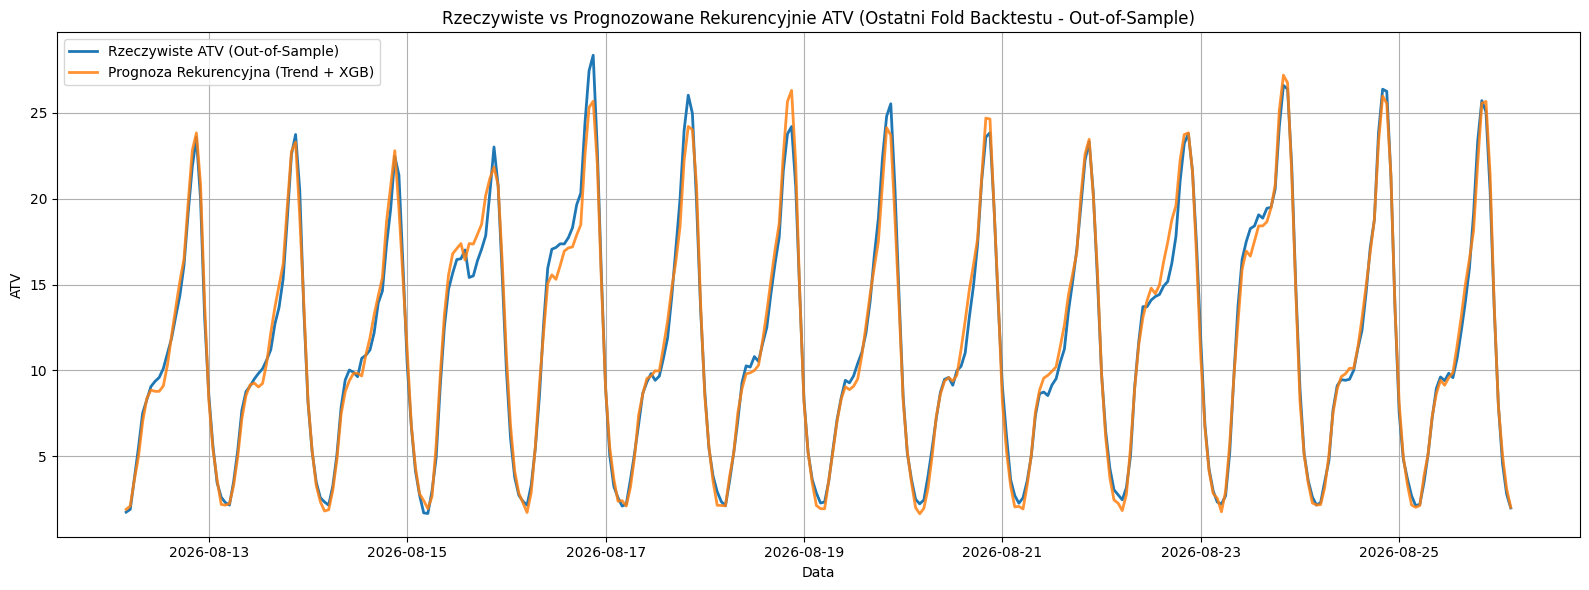

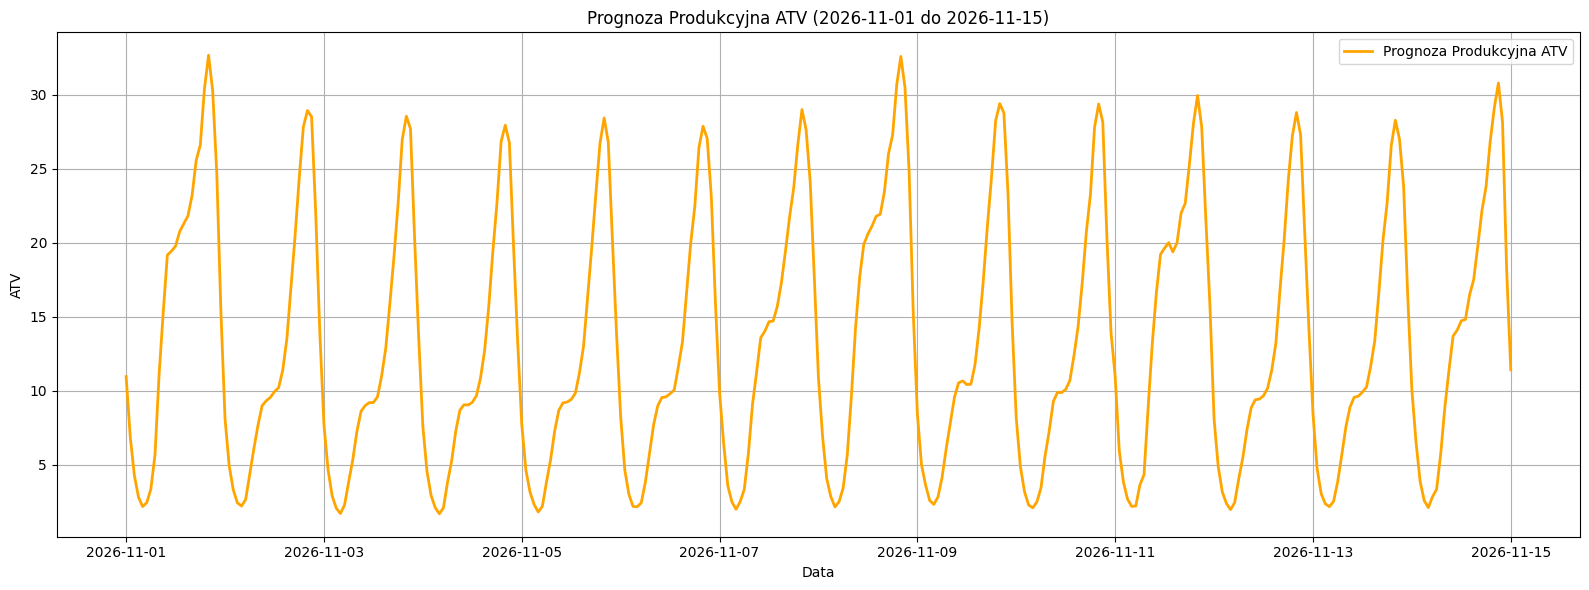

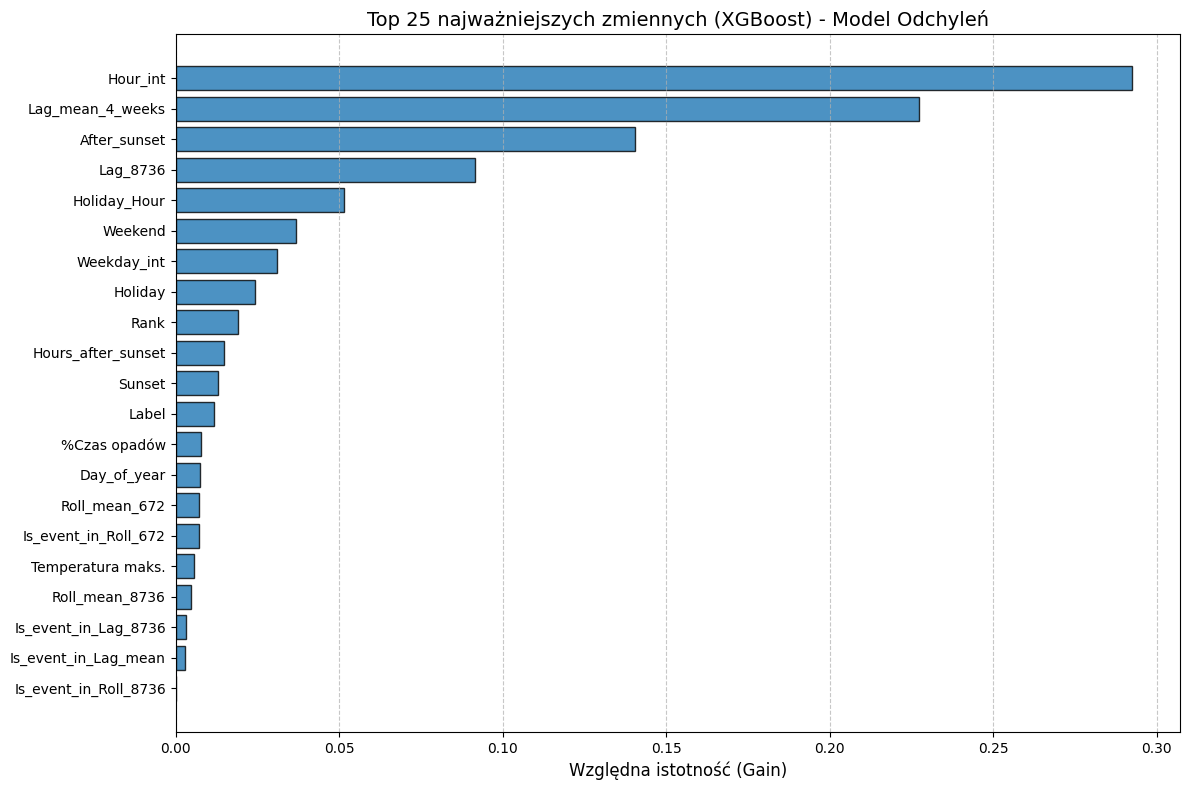

In [18]:
# 1. Wykres Out-of-Sample z ostatniego foldu Backtestu (zamiast obciążonego przeciekiem wykresu in-sample)
plot_bt = ostatni_fold_wyniki.iloc[:24 * 14].copy()  # Pierwsze 14 dni ostatniego foldu testowego
plt.figure(figsize=(16, 6))
plt.plot(plot_bt["DT"], plot_bt["ATV_actual"], label="Rzeczywiste ATV (Out-of-Sample)", linewidth=2)
plt.plot(plot_bt["DT"], plot_bt["ATV_predykcja"], label="Prognoza Rekurencyjna (Trend + XGB)", linewidth=2, alpha=0.85)
plt.title("Rzeczywiste vs Prognozowane Rekurencyjnie ATV (Ostatni Fold Backtestu - Out-of-Sample)")
plt.xlabel("Data")
plt.ylabel("ATV")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 2. Wykres Prognozy Produkcyjnej (pierwsze 14 dni prognozowanego miesiąca)
start_plot_pred = pd.to_datetime(Start_prognozowanego_miesiaca).tz_localize('UTC')
end_plot_pred = start_plot_pred + pd.Timedelta(days=14)
plot_forecast = prognoza.loc[(prognoza["DT"] >= start_plot_pred) & (prognoza["DT"] <= end_plot_pred)]

plt.figure(figsize=(16, 6))
plt.plot(plot_forecast["DT"], plot_forecast["ATV_predykcja"], linewidth=2, color="orange", label="Prognoza Produkcyjna ATV")
plt.title(f"Prognoza Produkcyjna ATV ({Start_prognozowanego_miesiaca} do {(Start_prognozowanego_miesiaca + timedelta(days=14))})")
plt.xlabel("Data")
plt.ylabel("ATV")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 3. Ważność Zmiennych (XGBoost - Model Odchyleń)
feature_importances = pd.DataFrame({
    'Zmienna': X_full.columns,
    'Istotność': final_xgb_model.feature_importances_
}).sort_values(by='Istotność', ascending=True)

plot_data = feature_importances.tail(25)
plt.figure(figsize=(12, 8))
plt.barh(plot_data['Zmienna'], plot_data['Istotność'], color='#1f77b4', edgecolor='black', alpha=0.8)
plt.title("Top 25 najważniejszych zmiennych (XGBoost) - Model Odchyleń", fontsize=14)
plt.xlabel("Względna istotność (Gain)", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [19]:
# %% [markdown]
# ## 9. Tabela Analityczna (In-Sample) - Analiza Błędów i Reszt
# 
# Tworzenie zbiorczej tabeli dla całej historii modelu z wartościami rzeczywistymi, dopasowanymi (fitted) oraz resztami.

# %%
print("Tworzenie tabeli analitycznej dla pełnej historii...")

# Kopiujemy pełną ramkę danych używaną do treningu ostatecznego modelu
df_analiza = df_model_full.copy()

# 1. Wyliczenie predykcji z obu modeli dla całego zbioru historycznego (In-Sample)
pred_trend = final_trend_model.predict(df_model_full[zmienne_trendu])
pred_xgb = final_xgb_model.predict(X_full)
pred_combined = pred_trend + pred_xgb

# 2. Odwrócenie transformacji, jeśli zmienna celu była logarytmowana
if zmienna_obj == "logATV":
    df_analiza["ATV_fitted"] = np.expm1(pred_combined)
else:
    df_analiza["ATV_fitted"] = pred_combined

# Obcięcie ewentualnych wartości ujemnych do zera (zgodnie z logiką - brak ujemnej oglądalności)
df_analiza["ATV_fitted"] = df_analiza["ATV_fitted"].clip(lower=0.0)

# 3. Przypisanie wartości rzeczywistych i wyliczenie błędów (reszt)
df_analiza["ATV_actual"] = df_analiza["ATV"]
df_analiza["Residual"] = df_analiza["ATV_actual"] - df_analiza["ATV_fitted"]
df_analiza["Residual_squared"] = df_analiza["Residual"] ** 2

# 4. Reorganizacja kolejności kolumn dla wygody analizy
# Najważniejsze metryki na początek, potem cała reszta cech modelu
kolumny_metryk = ["DT", "Date", "Time", "ATV_actual", "ATV_fitted", "Residual", "Residual_squared"]
pozostale_kolumny = [c for c in df_analiza.columns if c not in kolumny_metryk and c != "ATV" and c != "logATV"]

df_analiza = df_analiza[kolumny_metryk + pozostale_kolumny]

print(f"Wygenerowano tabelę analityczną o wymiarach: {df_analiza.shape[0]} wierszy i {df_analiza.shape[1]} kolumn.")

# Wyświetlenie próbki danych (5 wierszy z największym błędem kwadratowym)
print("\nTop 5 godzin z największym błędem modelu (najgorzej dopasowane):")
display(df_analiza.sort_values(by="Residual_squared", ascending=False).head(5))

# --- Opcjonalny eksport do pliku ---
# Odkomentuj poniższe linie, jeśli chcesz zapisać tę wielką tabelę do pliku CSV (zalecane, bo Excel może "klęknąć" przy dużej liczbie wierszy).
#
# if df_analiza["DT"].dt.tz is not None:
#     df_analiza["DT"] = df_analiza["DT"].dt.tz_localize(None)
# df_analiza.to_csv("Analiza_Reszt_Cala_Historia.csv", index=False, decimal=",")
# print("\nZapisano pełną tabelę analityczną do pliku: Analiza_Reszt_Cala_Historia.csv")

Tworzenie tabeli analitycznej dla pełnej historii...
Wygenerowano tabelę analityczną o wymiarach: 41902 wierszy i 49 kolumn.

Top 5 godzin z największym błędem modelu (najgorzej dopasowane):


,DT,Date,Time,ATV_actual,ATV_fitted,Residual,Residual_squared,Label,Rank,event_flag,...,Temperatura maks.,%Czas opadów,Lag_8736,Is_event_in_Lag_8736,Roll_mean_672,Is_event_in_Roll_672,Roll_mean_8736,Is_event_in_Roll_8736,Lag_mean_4_weeks,Is_event_in_Lag_mean
35085,2025-12-31 23:00:00+00:00,2025-12-31,23:00:00,32.609,25.411571,7.197429,51.802985,Brak,0.0,0,...,-4.984194,0.097701,17.791,0,14.242747,1,13.095396,1,15.97825,1
7934,2022-11-26 16:00:00+00:00,2022-11-26,16:00:00,30.535,23.929972,6.605028,43.626400,Brak,0.0,0,...,-3.451867,0.221868,25.071,0,14.501933,1,14.038738,1,19.82675,0
26325,2024-12-31 23:00:00+00:00,2024-12-31,23:00:00,32.287,26.065022,6.221978,38.713016,Brak,0.0,0,...,1.295806,-0.131499,18.509,0,14.684067,1,13.193030,1,17.17225,1
8036,2022-11-30 22:00:00+00:00,2022-11-30,22:00:00,30.998,25.315824,5.682176,32.287121,Brak,0.0,0,...,-5.691867,-0.145332,23.621,0,14.594426,1,14.035600,1,24.09750,0
15693,2023-10-15 23:00:00+00:00,2023-10-15,23:00:00,20.866,15.457494,5.408506,29.251934,Brak,0.0,0,...,-3.458554,-0.036372,15.296,0,12.788796,1,13.286425,1,14.07625,0
